# Decoding rescue of unassigned full-length reads

For each layout, a random subsample of unassigned full-length raw reads is compared with the printed whitelist by Hamming pre-filter and then sequence-Levenshtein distance. Dual barcodes and Zipcodes are also scored by exact 18-nt half matches.

Simulated recall at $r = 7$ is computed from the 1M combined decoding (true origin in the header; expected depth $10^6/85{,}305$).

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})
OUT = Path(".")

import decoding_rescue as dr

if not (OUT / "decoding_rescue_summary.csv").exists():
    dr.main()
summary = pd.read_csv(OUT / "decoding_rescue_summary.csv")
rescue = pd.read_csv(OUT / "decoding_rescue_subsample.csv")
display(summary.round(3))

,layout,unassigned_full_length,subsample,frac_lev_le7,frac_lev_le10,median_levenshtein,both_halves,half1_only,half2_only,neither_half
0,Dual barcodes,58015,15000,0.0,0.014,14.0,0.0,0.0,0.0,1.0
1,Greedy + 2-OPT,119273,15000,0.0,0.006,14.0,0.0,0.0,0.0,1.0
2,Zipcodes,105337,15000,0.0,0.006,15.0,0.0,0.0,0.0,1.0


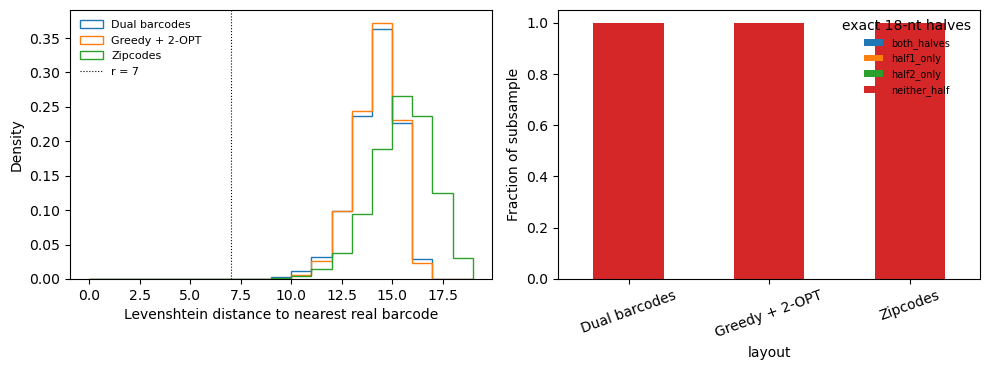

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for name, d in rescue.groupby("layout"):
    axes[0].hist(d.levenshtein, bins=range(0, 20), histtype="step", density=True, label=name)
axes[0].axvline(7, color="black", ls=":", lw=0.8, label="r = 7")
axes[0].set_xlabel("Levenshtein distance to nearest real barcode")
axes[0].set_ylabel("Density")
axes[0].legend(frameon=False, fontsize=8)
half_cols = ["both_halves", "half1_only", "half2_only", "neither_half"]
summary.set_index("layout")[half_cols].plot(kind="bar", stacked=True, ax=axes[1], rot=20)
axes[1].set_ylabel("Fraction of subsample")
axes[1].legend(frameon=False, fontsize=7, title="exact 18-nt halves")
fig.tight_layout()
fig.savefig(OUT / "decoding_rescue.pdf")
plt.show()